# Root-cause analysis of Transformer CO₂ forecasts

The absorber presents two coupled forecasting difficulties: concentration changes differ across sampling positions, and the rotating analyzer supplies each position with intermittent observations. The Transformer combines recent operating measurements with the last completed CO₂ dwell to predict a six-location concentration profile. Its principal observed failure is the magnitude and direction of the inferred concentration change. The analysis below traces that failure through measured temporal dynamics, spatial coupling, operating-condition sensitivity, measurement age, and held-out operating regimes. Conclusions are drawn from genuine measurements and saved out-of-experiment predictions.

In [1]:
from pathlib import Path
import io,zipfile,warnings
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from IPython.display import display,Markdown
plt.rcParams.update({'figure.dpi':115,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
HERE=Path.cwd(); SEARCH=[HERE,HERE.parent,Path('/mnt/data')]
rz=next((p/f for p in SEARCH for f in ['results(2).zip','results.zip'] if (p/f).exists()),None)
z=zipfile.ZipFile(rz) if rz else None

def result(rel):
 for base in SEARCH:
  p=base/'results'/rel
  if p.exists():return pd.read_csv(p)
 if z and 'results/'+rel in z.namelist():return pd.read_csv(io.BytesIO(z.read('results/'+rel)))
 raise FileNotFoundError('Missing results/'+rel+'; provide results/ or results(2).zip')

def raw_runs():
 for base in SEARCH:
  for d in [base/'data'/'raw',base/'rootcause_inputs',base/'raw']:
   if d.exists() and len(list(d.glob('*.xlsx')))>=8:
    out={}
    for p in sorted(d.glob('*.xlsx')):
     a=pd.read_excel(p,sheet_name=0,skiprows=[1]);a.columns=[str(x).strip() for x in a.columns];a=a.rename(columns={a.columns[0]:'timestamp'});a['timestamp']=pd.to_datetime(a.timestamp)
     out[p.stem.split('(')[0]+'.xlsx']=a.reset_index(drop=True)
    return out,d
 raise FileNotFoundError('Provide all eight raw Excel experiments in data/raw/.')
runs,rawdir=raw_runs()
FEATURES=['AT100','AT300','FT100','FT102','FT103','FT104','FT105','FT106','FT108','FT109','FT116','FT201','FT301','FT302','FT303','FT304','FT305','FT402','LT101','LT104','PDT105','PT110','PT402','PT403','TT100','TT102','TT200','TT210','TT211','TT213']
outer=result('earlystop_cv/outer_predictions.csv');final=result('final_test/final_predictions.csv')
dev=outer.query('history==12 and horizon==1 and training_objective=="noise" and input_mode=="combined"').copy()
test=final.copy()
def observed(df):
 d=df.loc[df.observed.eq(True)&df.valid.eq(True)&df.location.ne('L1')].copy()
 for col in ['y_true','y_pred','persistence_pred'] :d[col]=pd.to_numeric(d[col],errors='coerce')
 return d.dropna(subset=['y_true','y_pred'])
def pair(df):
 d=observed(df);return d[d.persistence_available.eq(True)].dropna(subset=['persistence_pred']).copy()
dev=pair(dev);test=pair(test)
for d in (dev,test):
 assert not d.duplicated(['experiment','target_row','location']).any()
 d['residual']=d.y_pred-d.y_true;d['base_residual']=d.persistence_pred-d.y_true
 d['actual_increment']=d.y_true-d.persistence_pred;d['model_correction']=d.y_pred-d.persistence_pred
 d['gain']=d.base_residual.abs()-d.residual.abs()
assert set(dev.experiment).isdisjoint(set(test.experiment)) and dev.experiment.nunique()==7 and test.experiment.nunique()==1
assert len(runs)==8 and set(dev.experiment).union(test.experiment)==set(runs)
print('Raw experiments:',len(runs),'| Development matched observations:',len(dev),'| Independent test matched:',len(test))
print('Raw source:',rawdir,'| Saved predictions:',rz or 'results/')

Raw experiments: 8 | Development matched observations: 549 | Independent test matched: 83
Raw source: /Users/niharikadeshpande/Downloads/co2_transformer_submission/data/raw | Saved predictions: /Users/niharikadeshpande/Downloads/co2_transformer_submission/results.zip


## 1 | The physical concentration signal is location-dependent

The analyzer sequentially visits the absorber sampling positions. Each visit produces several readings, but the next independent update at a given position arrives only on the following rotation. We therefore aggregate each completed dwell and calculate changes **between consecutive visits to the same location**. Absolute changes quantify the scale the forecasting head must represent; changes normalized by each experiment–location interquartile range separate relative dynamism from the large vertical concentration gradient. The revisit-time panel establishes the time scale over which those changes accumulate.

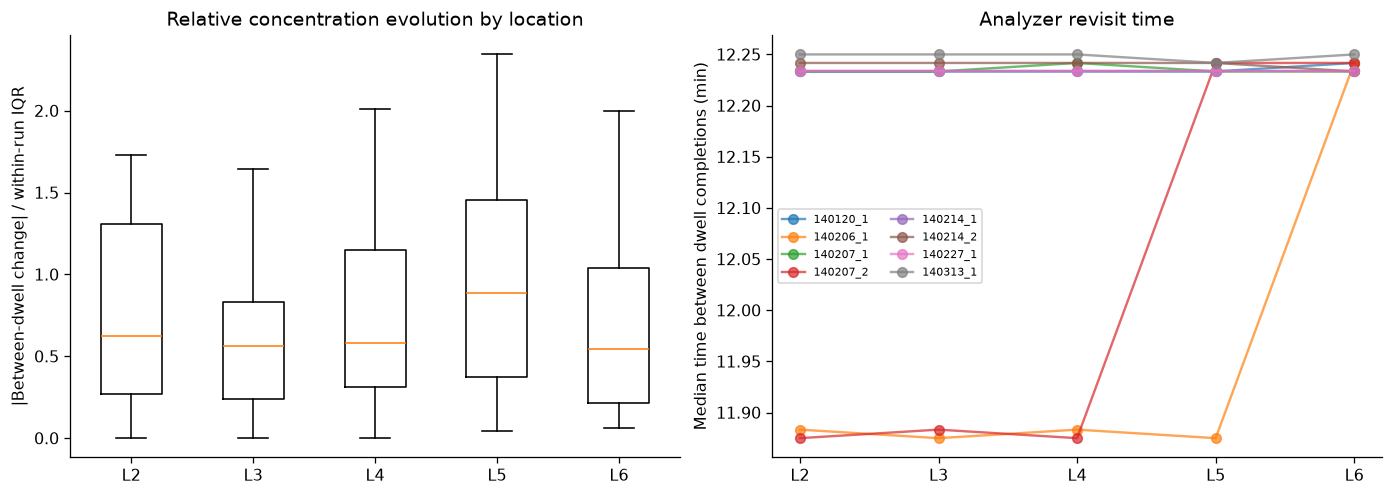

,experiment,location,n,median_interval_min,median_abs_change,p90_abs_change,median_scaled_change
0,140120_1.xlsx,L2,6,12.2333,0.0021,0.0126,0.8394
1,140120_1.xlsx,L3,6,12.2333,0.0249,0.0322,0.6674
2,140120_1.xlsx,L4,6,12.2333,0.0257,0.0368,0.6154
3,140120_1.xlsx,L5,6,12.2333,0.3029,1.7327,0.8924
4,140120_1.xlsx,L6,6,12.2417,0.8350,2.2817,0.8137
5,140206_1.xlsx,L2,2,11.8833,0.0275,0.0400,1.0000
6,140206_1.xlsx,L3,2,11.8750,0.0271,0.0413,1.2098
7,140206_1.xlsx,L4,2,11.8833,0.0014,0.0021,1.0000
8,140206_1.xlsx,L5,2,11.8750,0.3957,0.4828,1.5682
9,140206_1.xlsx,L6,2,12.2417,1.1302,1.2483,1.7689


,n,median_abs_change,p90_abs_change,median_scaled_change,median_interval_min
location,,,,,
L2,45,0.0014,0.0162,0.6216,12.2333
L3,45,0.0141,0.0390,0.5653,12.2333
L4,45,0.0158,0.1141,0.5784,12.2333
L5,45,0.1400,0.5361,0.8864,12.2333
L6,45,0.3439,1.1922,0.5444,12.2333


Across locations, median absolute between-dwell changes range from 0.0014 to 0.3439; median normalized changes range from 0.544 to 0.886.


In [2]:
obs=[]
for run,raw in runs.items():
    a=raw[['timestamp','label','AT400']].copy()
    a['AT400']=pd.to_numeric(a.AT400,errors='coerce')
    a['dwell_id']=a.label.ne(a.label.shift()).cumsum()
    dw=a.groupby('dwell_id',sort=True).agg(location=('label','first'),timestamp=('timestamp','max'),concentration=('AT400','mean'),n_samples=('AT400','count')).reset_index()
    for loc in range(2,7):
        b=dw.loc[dw.location.eq(loc)].sort_values('timestamp').copy()
        b['interval_min']=b.timestamp.diff().dt.total_seconds()/60
        b['delta']=b.concentration.diff()
        scale=b.concentration.quantile(.75)-b.concentration.quantile(.25)
        b['abs_delta_scaled']=b.delta.abs()/scale if scale>1e-10 else np.nan
        b['experiment']=run;b['location']=f'L{loc}'
        obs.append(b)
obs=pd.concat(obs,ignore_index=True)
changes=obs.dropna(subset=['delta','interval_min']).copy()
changes=changes[changes.interval_min>0]
changes['abs_delta']=changes.delta.abs();changes['rate']=changes.abs_delta/changes.interval_min
summary=changes.groupby(['experiment','location']).agg(n=('delta','size'),median_interval_min=('interval_min','median'),median_abs_change=('abs_delta','median'),p90_abs_change=('abs_delta',lambda x:x.quantile(.9)),median_scaled_change=('abs_delta_scaled','median')).reset_index()
fig,axs=plt.subplots(1,2,figsize=(12,4.2),constrained_layout=True)
locs=[f'L{i}' for i in range(2,7)]
axs[0].boxplot([changes.loc[changes.location.eq(k),'abs_delta_scaled'].dropna() for k in locs],tick_labels=locs,showfliers=False)
axs[0].set(ylabel='|Between-dwell change| / within-run IQR',title='Relative concentration evolution by location')
for run,g in summary.groupby('experiment'):
    axs[1].plot(locs,[g.set_index('location').median_interval_min.get(k,np.nan) for k in locs],marker='o',alpha=.7,label=run.replace('.xlsx',''))
axs[1].set(ylabel='Median time between dwell completions (min)',title='Analyzer revisit time');axs[1].legend(ncol=2,fontsize=7)
plt.show()
display(summary.round(4))
location_summary=changes.groupby('location').agg(n=('delta','size'),median_abs_change=('abs_delta','median'),p90_abs_change=('abs_delta',lambda x:x.quantile(.9)),median_scaled_change=('abs_delta_scaled','median'),median_interval_min=('interval_min','median'))
display(location_summary.round(4))
print(f"Across locations, median absolute between-dwell changes range from {location_summary.median_abs_change.min():.4f} to {location_summary.median_abs_change.max():.4f}; median normalized changes range from {location_summary.median_scaled_change.min():.3f} to {location_summary.median_scaled_change.max():.3f}.")

### Interpretation — spatial scale and observation interval

Across the eight runs, the median interval between completed visits is **12.23 minutes at every reported location**. This is substantially longer than the one-step forecast horizon (~43 seconds): the model makes a short-horizon prediction using a concentration reference that may have been acquired many logger steps earlier. The two time scales must not be conflated.

The median absolute **between-dwell** changes increase from **0.0014 at L2** to **0.3439 at L6**; the upper-decile change reaches **1.1922 at L6**. Absolute error is therefore intrinsically more sensitive to missed changes at the upper location. Normalizing each change by its own experiment–location IQR changes the ranking: **L5 has the largest median relative change (0.886)**, compared with **0.544 at L6**. L6's large absolute changes do not mean that it is the most dynamically unstable location relative to its own concentration range.

**Consequence for the model.** A single six-output head must learn concentration adjustments whose natural scales differ markedly by position. Large absolute corrections at L5–L6 may be necessary, but their magnitude must be conditional on the actual evolution of that location. The next section tests whether the fitted network makes that distinction.

## 2 | The model's immediate failure: excessive or misdirected concentration adjustments

For each observed forecast, write the model output as the last causally available dwell concentration plus a learned adjustment. The realized adjustment is the measured concentration minus that same anchor. This decomposition directly tests the model’s learned temporal response, independent of the absolute concentration level. The diagonal in the first figure represents an exact dynamic prediction; the second figure tests whether the correction is particularly damaging when the process changes little.

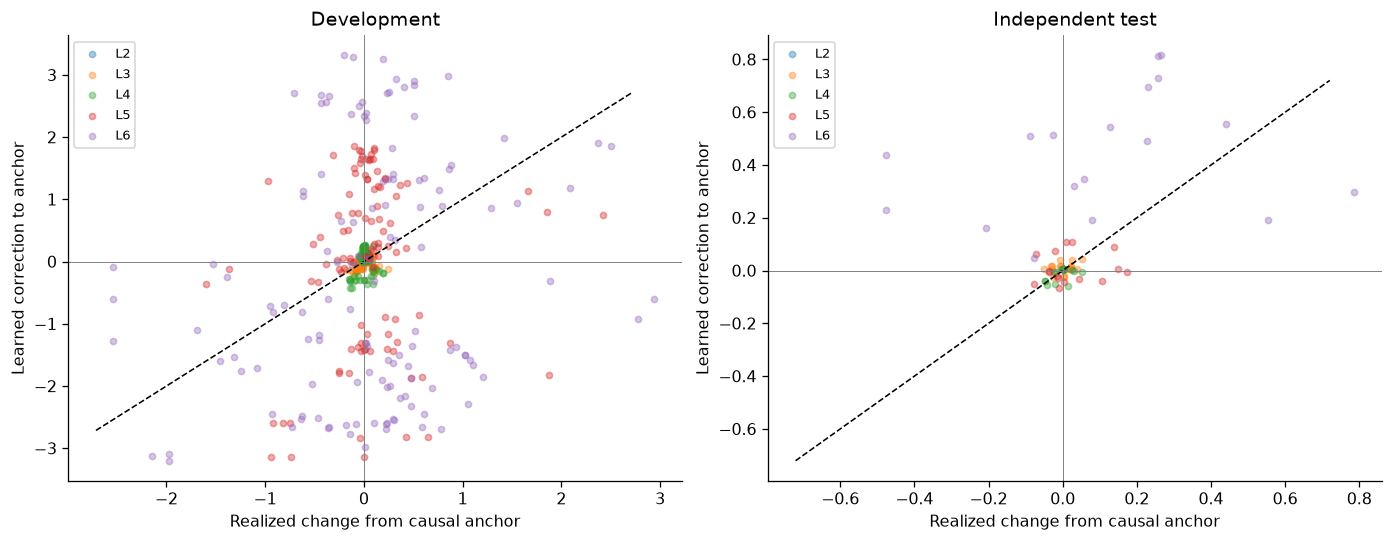

,split,location,n,n_active,direction_accuracy,median_actual_change,median_correction,correction_to_change,fraction_helpful,median_gain
0,Development,L2,117,95,0.600,0.002,0.006,2.730000e+00,0.342,-0.003
1,Development,L3,117,117,0.632,0.029,0.069,2.400000e+00,0.299,-0.034
2,Development,L4,80,74,0.473,0.019,0.150,8.004000e+00,0.138,-0.110
3,Development,L5,107,107,0.617,0.151,1.202,7.938000e+00,0.196,-0.926
4,Development,L6,128,128,0.562,0.455,1.695,3.724000e+00,0.273,-1.265
5,Independent test,L2,18,3,0.000,0.000,0.004,4.461463e+09,0.000,-0.004
6,Independent test,L3,18,18,0.500,0.024,0.018,7.420000e-01,0.500,-0.001
7,Independent test,L4,13,12,0.667,0.024,0.005,2.230000e-01,0.538,0.002
8,Independent test,L5,16,16,0.625,0.037,0.042,1.121000e+00,0.375,-0.020
9,Independent test,L6,18,18,0.667,0.229,0.464,2.025000e+00,0.167,-0.232


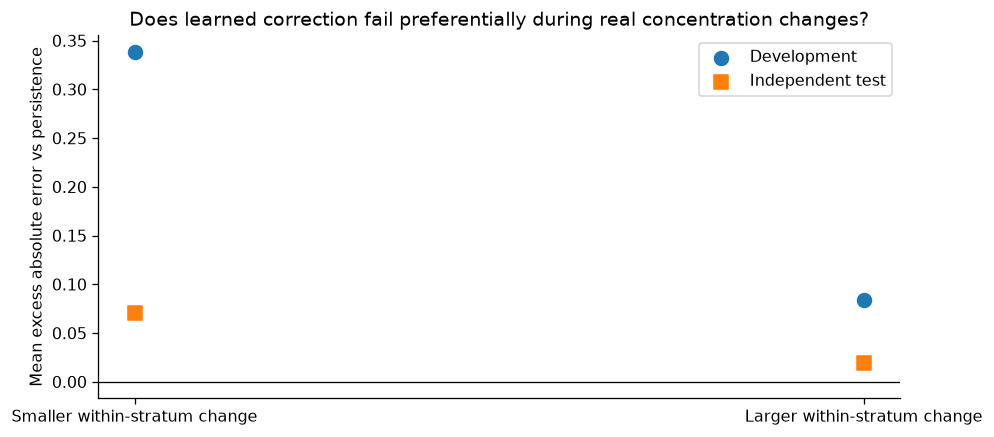

n_strata  mean_excess  mean_help_rate
split            change_group                                         
Development      Larger change         31        0.084           0.535
                 Smaller change        31        0.339           0.244
Independent test Larger change          4        0.019           0.482
                 Smaller change         4        0.070           0.315

In [3]:
from scipy.stats import binomtest
rows=[]
for split,d in [('Development',dev),('Independent test',test)]:
 for loc,g in d.groupby('location'):
  a=g.actual_increment.to_numpy();c=g.model_correction.to_numpy()
  active=np.abs(a)>1e-8
  signok=(np.sign(a[active])==np.sign(c[active])) if active.any() else np.array([])
  rows.append(dict(split=split,location=loc,n=len(g),n_active=int(active.sum()),direction_accuracy=signok.mean() if len(signok) else np.nan,
   median_actual_change=np.median(np.abs(a)),median_correction=np.median(np.abs(c)),correction_to_change=np.median(np.abs(c))/max(np.median(np.abs(a)),1e-12),
   fraction_helpful=(g.gain>0).mean(),median_gain=g.gain.median()))
correction=pd.DataFrame(rows)
fig,axs=plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)
for ax,(split,d) in zip(axs,[('Development',dev),('Independent test',test)]):
 for loc,g in d.groupby('location'):
  ax.scatter(g.actual_increment,g.model_correction,alpha=.38,s=15,label=loc)
 lim=np.nanquantile(np.abs(np.r_[d.actual_increment,d.model_correction]),.98)
 ax.plot([-lim,lim],[-lim,lim],color='black',ls='--',lw=1)
 ax.axhline(0,color='gray',lw=.6);ax.axvline(0,color='gray',lw=.6)
 ax.set(xlabel='Realized change from causal anchor',ylabel='Learned correction to anchor',title=split)
 ax.legend(fontsize=8)
plt.show()
display(correction.round(3))
# Compare within-run/location stable and changing observations (no pooled absolute thresholds across location scales).
parts=[]
for (split,run,loc),g in pd.concat([dev.assign(split='Development'),test.assign(split='Independent test')]).groupby(['split','experiment','location']):
 if len(g)<6 or g.actual_increment.abs().nunique()<3:continue
 q=g.actual_increment.abs().median()
 for label,h in [('Smaller change',g[g.actual_increment.abs()<=q]),('Larger change',g[g.actual_increment.abs()>q])]:
  if len(h):parts.append(dict(split=split,experiment=run,location=loc,change_group=label,n=len(h),help_rate=(h.gain>0).mean(),excess_error=-h.gain.mean()))
conditional=pd.DataFrame(parts)
fig,ax=plt.subplots(figsize=(9,4.1))
for split,marker in [('Development','o'),('Independent test','s')]:
 z=conditional[conditional.split.eq(split)].groupby('change_group').excess_error.agg(['mean','count'])
 ax.scatter([0 if k=='Smaller change' else 1 for k in z.index],z['mean'],s=75,marker=marker,label=split)
ax.axhline(0,color='black',lw=.8);ax.set(xticks=[0,1],xticklabels=['Smaller within-stratum change','Larger within-stratum change'],ylabel='Mean excess absolute error vs persistence',title='Does learned correction fail preferentially during real concentration changes?');ax.legend();plt.show()
display(conditional.groupby(['split','change_group']).agg(n_strata=('experiment','size'),mean_excess=('excess_error','mean'),mean_help_rate=('help_rate','mean')).round(3))

### Interpretation — excessive adjustments during relatively stable concentration periods

The Transformer's inferred correction is the difference between its forecast and the last completed-dwell CO₂ concentration available at the forecast origin. On development observations, the **median absolute correction** is **2.4 times the median absolute realized change at L3**, **8.0 times at L4**, **7.9 times at L5**, and **3.7 times at L6**. These ratios compare distributional summaries; they are **not** pointwise overprediction factors or regression slopes. At L2, realized changes are sufficiently small that a ratio is unstable, so absolute magnitudes are more informative.

The mismatch is not exclusively one of amplitude. Direction agreement is **47.3% at L4** and **56.2% at L6** in development. The learned correction reduces absolute error in **13.8%** of L4 and **27.3%** of L6 development forecasts. On the independent test, **3 of 18 (16.7%)** matched L6 corrections reduce error; the median absolute correction is **0.464**, versus a median realized change of **0.229**. These location-specific findings demonstrate that the model's adjustment is frequently miscalibrated in both direction and size.

Stratifying forecasts **within experiment and location** by the magnitude of the realized concentration change identifies where the failure is most consequential. The mean additional absolute error from the learned correction is **0.339** in the smaller-change strata, compared with **0.084** in the larger-change strata; correction helpfulness rises from **24.4%** to **53.5%**. The limited independent-test strata show the same ordering (**0.070** versus **0.019** additional error). The model is therefore most vulnerable when the observed concentration changes little: it often introduces a nontrivial adjustment without a corresponding measured change.

**Diagnosis carried forward.** The directly observed failure is **poor calibration of location- and state-dependent concentration increments**. The next analyses examine whether physical response variability, intermittent concentration measurements, and unfamiliar operating conditions help explain when those adjustments become unreliable.

## 3 | Why recent process measurements do not reliably resolve the missing CO₂ change

Gas and solvent flows, pressure and temperature influence absorption through coupled mass transfer and transport. Their effect on a particular sampling position need not be instantaneous, and the same sensor change can accompany different concentration responses in different operating regimes. We evaluate **within-run changes**, rather than pooled sensor and concentration levels, and summarize the sign and magnitude of the relationships across experiments. The analysis tests whether the observed process signals provide a stable, location-specific directional cue for the model.

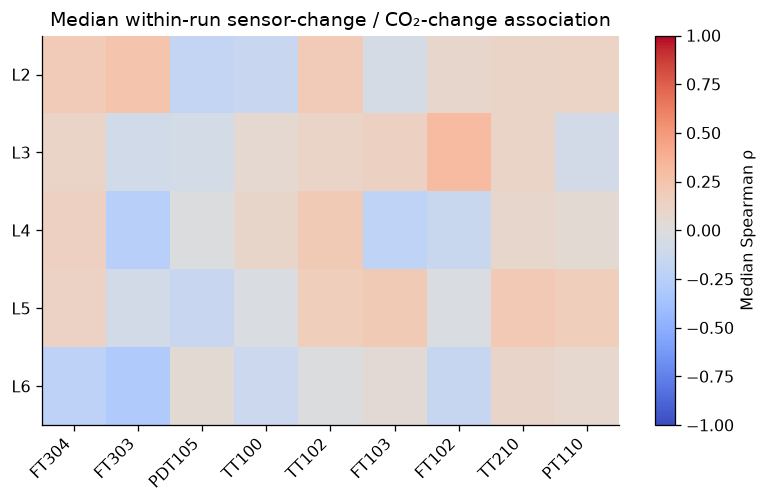

,location,variable,n_runs,median_rho,positive_fraction,median_abs_rho,sign_agreement
1,L2,FT102,8,0.088,0.500,0.343,0.500
2,L2,FT103,8,-0.061,0.250,0.175,0.750
8,L2,FT303,8,0.244,0.625,0.259,0.625
9,L2,FT304,8,0.195,0.625,0.351,0.625
10,L2,PDT105,8,-0.175,0.375,0.265,0.625
11,L2,PT110,8,0.122,0.625,0.242,0.625
13,L2,TT100,8,-0.144,0.375,0.245,0.625
14,L2,TT102,8,0.189,0.750,0.271,0.750
16,L2,TT210,8,0.110,0.625,0.265,0.625
18,L3,FT102,8,0.306,0.625,0.393,0.625


Median sign consistency for displayed cells: 0.75


In [4]:
# Use only variables that actually exist and have adequate variability.
CANDIDATES=['FT100','FT102','FT103','FT104','FT105','FT106','FT301','FT302','FT303','FT304','PT110','PT402','PDT105','TT100','TT102','TT200','TT210']
CANDIDATES=[v for v in CANDIDATES if all(v in r for r in runs.values())]
assoc=[]
for run,raw in runs.items():
 for loc in range(2,7):
  idx=np.flatnonzero(raw.label.to_numpy()==loc)
  vals=pd.to_numeric(raw.AT400.iloc[idx],errors='coerce').to_numpy()
  for v in CANDIDATES:
   sensor=pd.to_numeric(raw[v],errors='coerce').to_numpy()
   # A causal sensor interval change from the preceding genuine same-location measurement to the current measurement.
   dx=sensor[idx[1:]]-sensor[idx[:-1]];dy=np.diff(vals)
   ok=np.isfinite(dx)&np.isfinite(dy)
   if ok.sum()>=6 and np.nanstd(dx[ok])>1e-10 and np.nanstd(dy[ok])>1e-10:
    rho=spearmanr(dx[ok],dy[ok]).statistic
    if np.isfinite(rho):assoc.append(dict(experiment=run,location=f'L{loc}',variable=v,n=int(ok.sum()),rho=rho))
sens=pd.DataFrame(assoc)
if sens.empty:raise ValueError('No usable process-change relationships')
cons=sens.groupby(['location','variable']).agg(n_runs=('rho','size'),median_rho=('rho','median'),positive_fraction=('rho',lambda x:(x>0).mean()),median_abs_rho=('rho',lambda x:x.abs().median())).reset_index()
cons['sign_agreement']=cons.positive_fraction.clip(lower=.5).where(cons.positive_fraction>=.5,1-cons.positive_fraction)
# Only show variables with enough runs in at least three locations.
valid=cons[cons.n_runs>=4]
score=valid.groupby('variable').agg(n_locations=('location','nunique'),median_effect=('median_abs_rho','median'),median_consistency=('sign_agreement','median'))
selected=score[score.n_locations>=3].sort_values(['median_consistency','median_effect'],ascending=False).head(9).index.tolist()
heat=cons[cons.variable.isin(selected)].pivot(index='location',columns='variable',values='median_rho').reindex(index=[f'L{i}' for i in range(2,7)],columns=selected)
fig,ax=plt.subplots(figsize=(max(8,len(selected)*.9),4.4))
im=ax.imshow(heat.to_numpy(),cmap='coolwarm',vmin=-1,vmax=1,aspect='auto');ax.set(xticks=range(len(selected)),xticklabels=selected,yticks=range(5),yticklabels=heat.index,title='Median within-run sensor-change / CO₂-change association')
plt.setp(ax.get_xticklabels(),rotation=45,ha='right');plt.colorbar(im,ax=ax,label='Median Spearman ρ');plt.show()
display(valid[valid.variable.isin(selected)].sort_values(['location','variable']).round(3))
print('Median sign consistency for displayed cells:',round(valid[valid.variable.isin(selected)].sign_agreement.median(),3))

### Interpretation — process–concentration response varies by experiment

The location-by-sensor heatmap shows both positive and negative **within-experiment** associations between operating-variable changes and measured CO₂ changes. Several pairs reverse sign between runs. Among the displayed better-supported pairs, median sign agreement is **0.75**; the analysis therefore does not identify a stable, universally signed *single-variable* response. The result applies to the measured sensors, tested lags, and rank-association summaries—not to all possible multivariate or nonlinear process relationships.

In a countercurrent gas–liquid absorber, a location's CO₂ response reflects gas loading, solvent contact, temperature-dependent absorption behavior, and transport of changes along the column. A change in one measured flow or temperature need not produce the same local response under different operating conditions. The observed sign reversals are compatible with this coupled, regime-dependent behavior, although they do not identify a transport delay or reaction parameter.

**Connection to the correction error.** A model using recent process measurements to adjust an older concentration reference must infer a conditional, location-specific response. The absence of a consistently signed univariate proxy makes that inference less straightforward across experiments. It is a plausible contributing condition, **not proof that the process measurements contain no transferable predictive signal**.

## 4 | Sequential sampling creates a stale location-specific concentration state

The historical concentration supplied to the model becomes available only when a location's dwell has completed. We reconstruct that availability event from the analyzer sequence and check the resulting anchors against the saved forecast reference values. We then compare, within each experiment and location, how elapsed observation age relates to (i) the true change since the anchor and (ii) the model's excess error. These two relationships distinguish a stale signal that accompanies real process evolution from a model error that merely correlates with analyzer rotation.

Development verified completed-dwell anchors: 549 max absolute difference: 4.8e-07
Independent test verified completed-dwell anchors: 83 max absolute difference: 8e-08


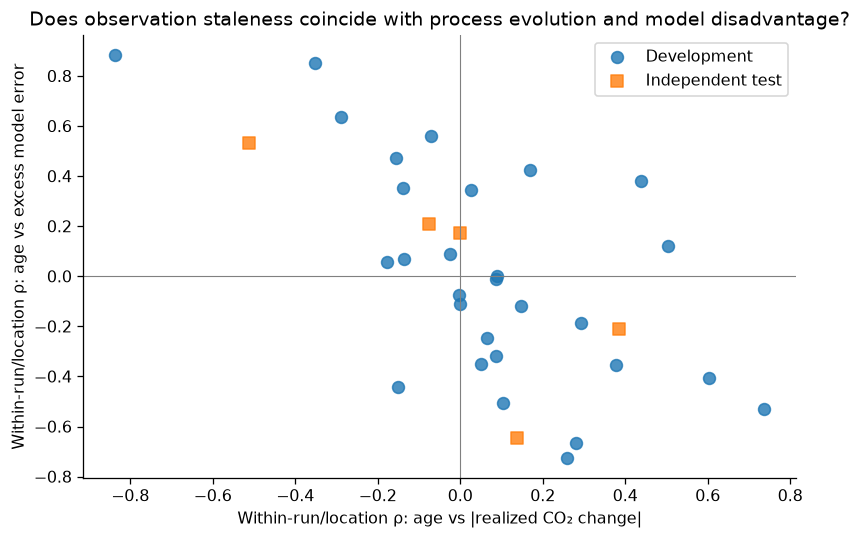

,split,experiment,location,n,rho_age_actual_change,rho_age_excess_error
0,Development,140120_1.xlsx,L2,18,0.087,-0.011
1,Development,140120_1.xlsx,L3,18,0.503,0.121
2,Development,140120_1.xlsx,L5,17,-0.135,0.069
3,Development,140120_1.xlsx,L6,18,-0.156,0.472
4,Development,140206_1.xlsx,L2,6,-0.152,-0.441
5,Development,140206_1.xlsx,L3,6,0.087,-0.319
6,Development,140206_1.xlsx,L5,6,-0.290,0.638
7,Development,140206_1.xlsx,L6,6,-0.353,0.853
8,Development,140207_2.xlsx,L2,6,0.379,-0.353
9,Development,140207_2.xlsx,L3,6,0.603,-0.406


In [5]:
def attach_age(d):
 parts=[]
 for run,g in d.groupby('experiment'):
  raw=runs[run];times=pd.to_datetime(raw.timestamp);labels=raw.label.to_numpy(int);vals=pd.to_numeric(raw.AT400,errors='coerce').to_numpy(float)
  # Mirror context.py: a dwell becomes available only when the next location begins.
  available={j:[] for j in range(2,7)};start=0
  for t in range(1,len(raw)):
   if labels[t]!=labels[t-1]:
    j=labels[t-1]
    if j>=2 and np.isfinite(vals[start:t]).any():
     available[j].append((t,t-1,float(np.nanmean(vals[start:t]))))
    start=t
  for loc,sub in g.groupby('location'):
   j=int(loc[1:]);dwell=available[j];ends=np.array([x[0] for x in dwell],int)
   o=sub.origin_row.to_numpy(int);ix=np.searchsorted(ends,o,side='right')-1
   valid=ix>=0;h=sub.copy();h['anchor_row']=-1;h['age_minutes']=np.nan;h['raw_anchor_value']=np.nan
   if valid.any():
    records=[dwell[k] for k in ix[valid]];last=np.array([r[1] for r in records],int)
    h.loc[valid,'anchor_row']=last
    h.loc[valid,'age_minutes']=(times.iloc[o[valid]].to_numpy()-times.iloc[last].to_numpy())/np.timedelta64(1,'m')
    h.loc[valid,'raw_anchor_value']=[r[2] for r in records]
   parts.append(h)
 return pd.concat(parts,ignore_index=True)

a_dev=attach_age(dev);a_test=attach_age(test)
for split,d in [('Development',a_dev),('Independent test',a_test)]:
 diff=(d.raw_anchor_value-d.persistence_pred).abs().dropna()
 assert len(diff)==len(d) and diff.max()<1e-4, f'Completed-dwell reconstruction mismatch: {split}'
 print(split,'verified completed-dwell anchors:',len(diff),'max absolute difference:',round(diff.max(),8))
from scipy.stats import spearmanr
age_rows=[]
for (split,run,loc),g in pd.concat([a_dev.assign(split='Development'),a_test.assign(split='Independent test')]).groupby(['split','experiment','location']):
 g=g.dropna(subset=['age_minutes'])
 if len(g)<5 or g.age_minutes.nunique()<4:continue
 age_rows.append(dict(split=split,experiment=run,location=loc,n=len(g),
  rho_age_actual_change=spearmanr(g.age_minutes,g.actual_increment.abs()).statistic,
  rho_age_excess_error=spearmanr(g.age_minutes,-g.gain).statistic))
age_stats=pd.DataFrame(age_rows)
fig,ax=plt.subplots(figsize=(8,5))
for split,mark in [('Development','o'),('Independent test','s')]:
 g=age_stats[age_stats.split.eq(split)]
 ax.scatter(g.rho_age_actual_change,g.rho_age_excess_error,marker=mark,s=55,alpha=.8,label=split)
ax.axhline(0,color='gray',lw=.7);ax.axvline(0,color='gray',lw=.7)
ax.set(xlabel='Within-run/location ρ: age vs |realized CO₂ change|',ylabel='Within-run/location ρ: age vs excess model error',title='Does observation staleness coincide with process evolution and model disadvantage?');ax.legend();plt.show()
display(age_stats.round(3))

### Interpretation — observation age is a real input constraint, but not a sufficient standalone cause

The reconstructed completed-dwell concentrations reproduce the saved anchors for **all 549 development and 83 independent-test matched observations**, with maximum discrepancies below **5×10⁻⁷** and **1×10⁻⁷**, respectively. Thus, the age analysis uses the same information boundary as the model rather than a retrospectively chosen measurement.

The scatter shows heterogeneous age relationships across experiment–location groups: several groups have a positive association between age and realized concentration change, while others have weak or negative associations. The corresponding association with the model's excess error is also variable. A longer time since the last measurement does not mechanically imply a larger concentration change; the effect depends on what the absorber did during that interval. The sparse short experiments contribute only a few eligible forecasts, so their individual correlation coefficients are particularly unstable.

**Root-cause implication.** Sequential analyzer rotation creates an **information gap** between current process measurements and the last known CO₂ state. That gap exposes the network to unobserved concentration evolution, but age alone does not determine the direction or size of the error. The more immediate failure remains the model's conditional correction, as demonstrated above.

## 5 | Training coverage and operating-regime mismatch

A model can learn a response pattern in one region of process-state space yet apply it incorrectly elsewhere. We fit the process-state transformation on the other development runs for each held-out experiment, and on development runs for the independent test. Nearest-neighbor distance measures departure from the available training states. The relevant diagnostic is not distance alone but whether **the Transformer's own absolute residual** grows within a held-out run as its operating state becomes less familiar.

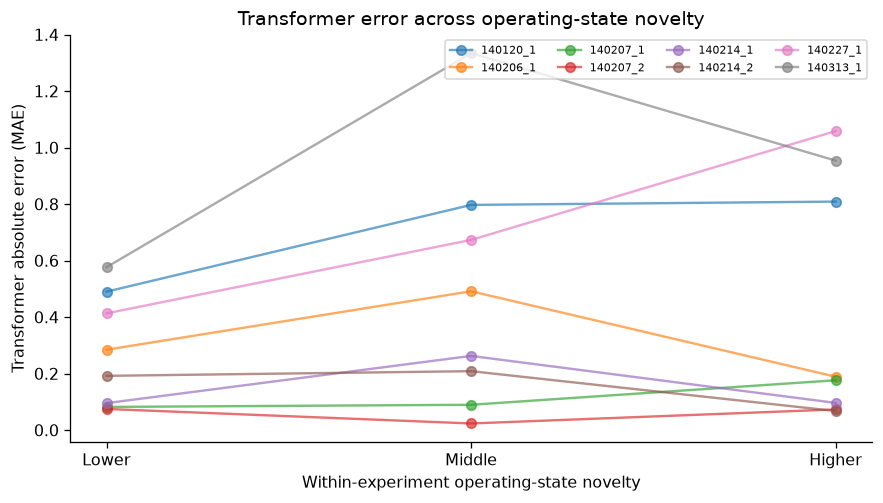

,experiment,training_median_nn,held_median_nn,ratio
0,140120_1.xlsx,0.741,3.702,4.999
1,140206_1.xlsx,0.730,1.879,2.573
2,140207_1.xlsx,0.729,2.149,2.949
3,140207_2.xlsx,0.716,2.125,2.966
4,140214_1.xlsx,0.745,4.294,5.768
5,140214_2.xlsx,0.713,2.091,2.934
6,140227_1.xlsx,0.748,2.756,3.687
7,140313_1.xlsx,0.684,6.739,9.850


,experiment,novelty_bin,n,model_mae,mean_signed_error
0,140120_1.xlsx,Lower,27,0.4903,-0.3840
1,140120_1.xlsx,Middle,28,0.7974,-0.1007
2,140120_1.xlsx,Higher,28,0.8091,-0.4209
3,140206_1.xlsx,Lower,9,0.2847,0.1410
4,140206_1.xlsx,Middle,9,0.4917,0.4883
5,140206_1.xlsx,Higher,10,0.1892,0.1446
6,140207_1.xlsx,Lower,27,0.0823,0.0550
7,140207_1.xlsx,Middle,28,0.0899,0.0052
8,140207_1.xlsx,Higher,28,0.1767,0.1489
9,140207_2.xlsx,Lower,9,0.0751,-0.0077


,experiment,rho_abs_error,rho_excess_error,n
0,140120_1.xlsx,0.126,0.198,83
1,140206_1.xlsx,-0.006,-0.033,28
2,140207_1.xlsx,0.148,0.305,83
3,140207_2.xlsx,0.123,-0.100,28
4,140214_1.xlsx,-0.029,0.198,41
5,140214_2.xlsx,-0.458,-0.299,28
6,140227_1.xlsx,0.154,0.187,165
7,140313_1.xlsx,0.098,0.228,176


**Finding.** Transformer absolute-error association with operating-state novelty is positive in **5/8** experiments (within-run Spearman coefficients). The held-out/training nearest-neighbor median ratios range from **2.57 to 9.85**. A positive association indicates that errors increase in less familiar operating conditions within that run.

In [6]:
def origins_for(df):
 a=[]
 for run,g in df.groupby('experiment'):
  x=runs[run]
  ids=g.origin_row.astype(int).to_numpy()
  assert ids.min()>=0 and ids.max()<len(x)
  y=x.loc[ids,FEATURES].apply(pd.to_numeric,errors='coerce').reset_index(drop=True)
  y['experiment']=run;y['origin_row']=ids
  a.append(y)
 return pd.concat(a,ignore_index=True).drop_duplicates(['experiment','origin_row'])
all_origins={k:r[FEATURES].apply(pd.to_numeric,errors='coerce').iloc[11:-1].copy() for k,r in runs.items()}
# The reference uses eligible origins from each run; no target measurements or target-time sensors.
def novelty(target,train_names):
 tr=pd.concat([all_origins[k] for k in train_names],ignore_index=True)
 med=tr.median().fillna(0);tr=tr.ffill().fillna(med)
 held=runs[target][FEATURES].apply(pd.to_numeric,errors='coerce').ffill().fillna(med)
 scaler=StandardScaler().fit(tr);xt=scaler.transform(tr);xh=scaler.transform(held)
 pca=PCA(n_components=min(8,len(FEATURES),len(tr)-1),random_state=42).fit(xt)
 t=pca.transform(xt);h=pca.transform(xh)
 nn=NearestNeighbors(n_neighbors=2).fit(t)
 training_nn=nn.kneighbors(t,n_neighbors=2)[0][:,1]
 held_nn=nn.kneighbors(h,n_neighbors=1)[0][:,0]
 return held_nn,training_nn
rows=[];reference=[]
for held in sorted(runs):
 train_names=[k for k in runs if k!=held] if held!='140207_1.xlsx' else sorted(set(dev.experiment))
 hd,tr=novelty(held,train_names)
 reference.append({'experiment':held,'training_median_nn':np.median(tr),'held_median_nn':np.median(hd),'ratio':np.median(hd)/max(np.median(tr),1e-12)})
 g=(test if held=='140207_1.xlsx' else dev)
 g=g[g.experiment.eq(held)].copy();g['novelty']=hd[g.origin_row.to_numpy(int)]
 rows.append(g)
nov=pd.concat(rows,ignore_index=True);ref=pd.DataFrame(reference)
nov['novelty_rank']=nov.groupby('experiment')['novelty'].rank(pct=True)
nov['novelty_bin']=pd.cut(nov.novelty_rank,[0,1/3,2/3,1.001],labels=['Lower','Middle','Higher'],include_lowest=True)
bybin=nov.groupby(['experiment','novelty_bin'],observed=True).agg(n=('gain','size'),model_mae=('residual',lambda x:x.abs().mean()),mean_signed_error=('residual','mean')).reset_index()
fig,ax=plt.subplots(figsize=(9,4.6))
for run,g in bybin.groupby('experiment'):
 ax.plot([0,1,2],[g.set_index('novelty_bin').model_mae.get(k,np.nan) for k in ['Lower','Middle','Higher']],marker='o',alpha=.65,label=run.replace('.xlsx',''))
ax.set_xticks(range(3),['Lower','Middle','Higher']);ax.set_ylabel('Transformer absolute error (MAE)');ax.set_xlabel('Within-experiment operating-state novelty');ax.set_title('Transformer error across operating-state novelty');ax.legend(ncol=4,fontsize=7);plt.show()
display(ref.round(3));display(bybin.round(4))
slopes=[]
for run,g in nov.groupby('experiment'):
 if g.novelty.nunique()>2:slopes.append((run,spearmanr(g.novelty,g.residual.abs()).statistic,spearmanr(g.novelty,-g.gain).statistic,len(g)))
slope=pd.DataFrame(slopes,columns=['experiment','rho_abs_error','rho_excess_error','n']);display(slope.round(3))
pos=(slope.rho_abs_error>0).sum();display(Markdown(f'**Finding.** Transformer absolute-error association with operating-state novelty is positive in **{pos}/{len(slope)}** experiments (within-run Spearman coefficients). The held-out/training nearest-neighbor median ratios range from **{ref.ratio.min():.2f} to {ref.ratio.max():.2f}**. A positive association indicates that errors increase in less familiar operating conditions within that run.'))

### Interpretation — extrapolation in process-state space contributes unevenly

The median held-out nearest-neighbor distance exceeds the within-training reference median in every experiment, by factors of **2.57–9.85**. The largest discrepancy is **140313_1 (9.85×)**; the independent test is **140207_1 (2.95×)**. These are relative geometric coverage diagnostics in the fitted feature representation, not calibrated probabilities of extrapolation.

Within-run novelty–absolute-error associations are positive in **5 of 8 experiments**, but the pattern is not uniform. In **140227_1**, Transformer MAE rises from **0.413** in the lowest novelty third to **1.059** in the highest; in **140313_1**, it rises from **0.577** to **1.335** in the middle third and then falls to **0.954** in the highest. Conversely, **140214_2** shows lower error at the highest novelty levels. The test experiment rises from **0.082** to **0.177** between its lowest and highest novelty thirds.

**Root-cause implication.** Training-state mismatch is a **contributing, experiment-dependent amplifier**, not a complete explanation of model error. It is consistent with the unstable process–CO₂ relationships found above: a learned adjustment can become unreliable when applied outside the process states that informed it. Because novelty is observational and correlated with other operating changes, it should not be treated as an isolated causal effect.

## 6 | Does the error follow a reproducible physical operating condition?

The mechanistic absorber model identifies throughput, solvent contact, temperature and pressure as plausible drivers of concentration evolution. A physical explanation of model bias would require residuals to vary reproducibly with these conditions, not merely correlate with one sensor in one run. We examine signed forecast residuals against **forecast-origin** process measurements separately for each experiment and location, then require both nontrivial association strength and cross-run directional agreement. Sensor tags are retained where their physical assignment or engineering units are not independently verified.

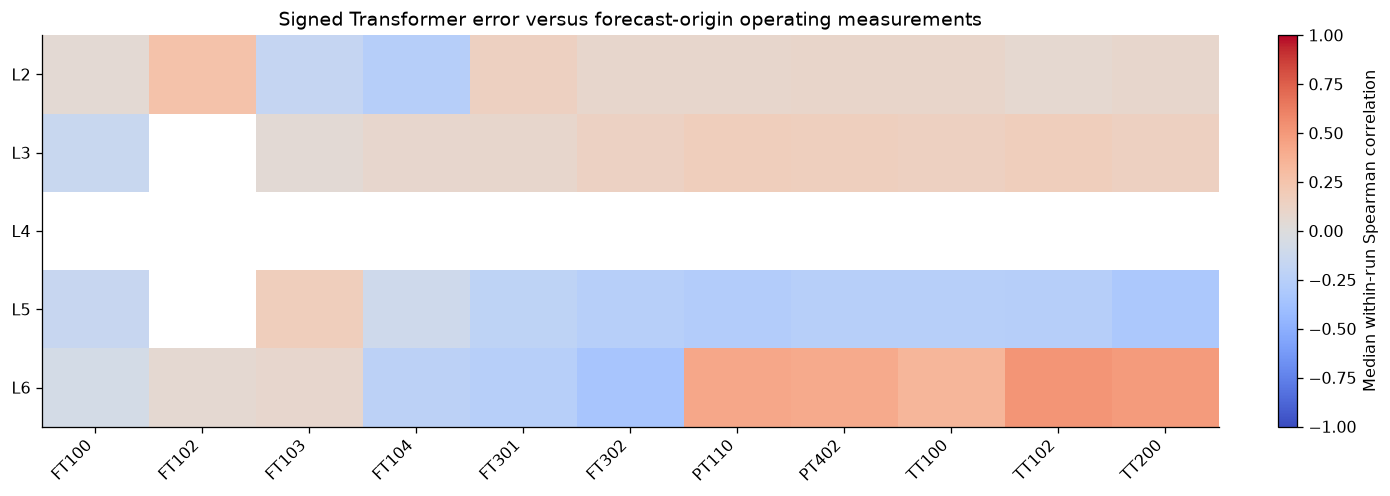

Consistent associations meeting ≥4 runs, median |ρ|≥0.30 and ≥80% sign agreement: 0/42 eligible location/sensor pairs.


,location,variable,n_runs,median_rho,median_abs_rho,sign_consistency


No L6 sensor meets the predeclared cross-run stability criteria; a single sensor cannot be assigned as the dominant L6 bias driver.


In [7]:
# Sensor-to-physical-quantity mapping is intentionally conservative: sensor tags are retained
# unless their engineering units and roles have been verified independently.
REGIME_SENSORS=[v for v in ['FT100','FT102','FT103','FT104','FT301','FT302','PT110','PT402','TT100','TT102','TT200'] if all(v in x.columns for x in runs.values())]
all_forecasts=pd.concat([dev.assign(split='Development'),test.assign(split='Independent test')],ignore_index=True)
regime=[]
for run,g in all_forecasts.groupby('experiment'):
    raw=runs[run]
    for v in REGIME_SENSORS:
        values=pd.to_numeric(raw[v],errors='coerce').to_numpy()
        x=g.copy();x['variable']=v;x['sensor_at_origin']=values[x.origin_row.to_numpy(dtype=int)]
        regime.append(x[['split','experiment','location','variable','sensor_at_origin','residual','actual_increment','model_correction']])
regime=pd.concat(regime,ignore_index=True).dropna(subset=['sensor_at_origin','residual'])
regime_rows=[]
for (split,run,loc,v),g in regime.groupby(['split','experiment','location','variable']):
    if len(g)<7 or g.sensor_at_origin.nunique()<5:continue
    rho=spearmanr(g.sensor_at_origin,g.residual).statistic
    if not np.isfinite(rho):continue
    q1,q3=g.sensor_at_origin.quantile([.25,.75])
    lower=g.loc[g.sensor_at_origin<=q1,'residual'];upper=g.loc[g.sensor_at_origin>=q3,'residual']
    regime_rows.append(dict(split=split,experiment=run,location=loc,variable=v,n=len(g),rho_signed_error=rho,
                            high_minus_low_bias=upper.mean()-lower.mean(),low_n=len(lower),high_n=len(upper)))
regime_stats=pd.DataFrame(regime_rows)
if regime_stats.empty:raise ValueError('Insufficient sensor variability for regime analysis')
run_support=regime_stats.query('split=="Development"').groupby(['location','variable']).agg(
    n_runs=('rho_signed_error','size'),median_rho=('rho_signed_error','median'),
    median_abs_rho=('rho_signed_error',lambda x:x.abs().median()),
    positive_fraction=('rho_signed_error',lambda x:(x>0).mean())).reset_index()
run_support['sign_consistency']=run_support.positive_fraction.clip(lower=.5).where(run_support.positive_fraction>=.5,1-run_support.positive_fraction)
run_support['eligible']=run_support.n_runs>=4
eligible=run_support[run_support.eligible]
# Display all eligible sensors rather than selecting only the largest correlations.
mat=eligible.pivot(index='location',columns='variable',values='median_rho').reindex(index=[f'L{i}' for i in range(2,7)],columns=REGIME_SENSORS)
fig,ax=plt.subplots(figsize=(12,4.2),constrained_layout=True)
im=ax.imshow(mat.to_numpy(),cmap='coolwarm',vmin=-1,vmax=1,aspect='auto')
ax.set(xticks=np.arange(len(mat.columns)),xticklabels=mat.columns,yticks=np.arange(len(mat.index)),yticklabels=mat.index,
       title='Signed Transformer error versus forecast-origin operating measurements')
plt.setp(ax.get_xticklabels(),rotation=45,ha='right');fig.colorbar(im,ax=ax,label='Median within-run Spearman correlation');plt.show()
strong_regime=eligible.query('median_abs_rho >= 0.3 and sign_consistency >= 0.8').sort_values(['sign_consistency','median_abs_rho'],ascending=False)
print(f'Consistent associations meeting ≥4 runs, median |ρ|≥0.30 and ≥80% sign agreement: {len(strong_regime)}/{len(eligible)} eligible location/sensor pairs.')
display(strong_regime[['location','variable','n_runs','median_rho','median_abs_rho','sign_consistency']].round(3))
# A targeted L6 diagnostic: show the strongest stable association, if any, and independent-test contrast.
choices=strong_regime.query('location=="L6"')
if not choices.empty:
    chosen=choices.iloc[0].variable
    q=regime_stats.query('location=="L6" and variable==@chosen')
    print(f'L6 strongest recurrent association: {chosen}; development median ρ={choices.iloc[0].median_rho:+.3f} across {int(choices.iloc[0].n_runs)} runs.')
    display(q[['split','experiment','n','rho_signed_error','high_minus_low_bias']].round(3))
else:
    print('No L6 sensor meets the predeclared cross-run stability criteria; a single sensor cannot be assigned as the dominant L6 bias driver.')

### Interpretation — no reproducible single-sensor signature of the residual

Under the prespecified screen—at least four eligible experiments, median absolute within-run Spearman correlation ≥0.30, and sign agreement ≥80%—**none of the 42 eligible sensor–location pairs qualifies**. In particular, no tested L6 sensor shows a sufficiently consistent signed-residual association across runs. This rules out a simple, reproducible *univariate contemporaneous* explanation of the errors within the examined variables and temporal alignment.

The negative result is physically informative. Gas/liquid throughput, temperature, and pressure jointly affect absorption and residence-time-dependent responses; individual sensor tags are imperfect proxies for those coupled states. An instantaneous sensor–residual correlation cannot isolate a delayed, multivariable transport or mass-transfer mechanism. Thus the evidence does not justify attributing the error to one faulty sensor, a universal flow sensitivity, or a particular kinetic parameter.

**Implication for the fitted model.** Together with the cross-run sign changes in observed process–CO₂ relationships, this screen supports the interpretation that the Transformer's learned corrections are **insufficiently robust to context-dependent process responses**. It does not exclude informative combinations of operating measurements or more appropriate temporal alignments.

## 7 | Spatial coupling and location-dependent forecast response

Gas travels through the absorber while solvent flows countercurrently. Concentrations at neighboring positions are therefore physically coupled, although the sequential analyzer does not measure the six locations simultaneously. The model produces six concentrations at each forecast origin. We examine the **spatial structure of those simultaneous model outputs**, then compare the forecast at the genuinely observed position with the **last completed dwell values at neighboring positions**. This separates what the model predicts about the column from what the analyzer actually verifies.

Two diagnostics are useful: (i) the frequency and magnitude of predicted inversions between adjacent locations L2–L6, and (ii) whether the observed-location error changes when the model's spatial gradient disagrees with the most recently observed neighboring gradient. The second diagnostic is conditional on measurement age: a stale neighbor is an imperfect reference, not simultaneous ground truth.

Predicted complete spatial profiles: 802


,n,fraction_with_inversion,median_max_inversion
dataset,,,
Development,696,0.478,0.0
Independent test,106,0.132,0.0


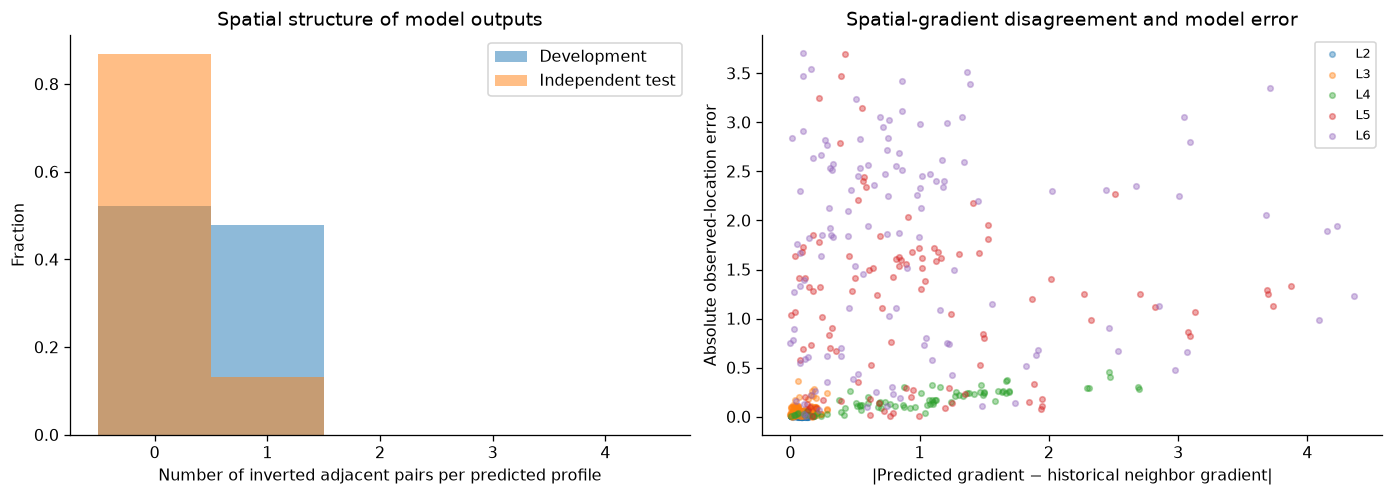

,dataset,location,n,rho_disagreement_error,median_neighbor_age_rows,median_gradient_disagreement
0,Development,L2,117,-0.009,12.0,0.061
1,Development,L3,117,0.204,13.0,0.096
2,Development,L4,80,0.858,13.0,0.990
3,Development,L5,107,-0.024,12.0,0.792
4,Development,L6,128,0.087,2.0,0.750
5,Independent test,L2,18,0.018,12.0,0.013
6,Independent test,L3,18,-0.484,13.0,0.035
7,Independent test,L4,13,0.610,13.0,0.055
8,Independent test,L5,16,-0.024,12.0,0.311
9,Independent test,L6,18,0.294,2.0,0.411


Spatial gradient comparison is historical/asynchronous; it is not an observed simultaneous spatial profile.


In [8]:
# Spatial predictions at each forecast origin; no reconstructed targets are used as truth.
sel=outer.query('history==12 and horizon==1 and training_objective=="noise" and input_mode=="combined"').copy()
sel=pd.concat([sel.assign(dataset='Development'),final.assign(dataset='Independent test')],ignore_index=True)
sel=sel[sel.location.isin([f'L{i}' for i in range(2,7)])].copy()
sel['loc_num']=sel.location.str[1:].astype(int)
profiles=sel.pivot_table(index=['dataset','experiment','origin_row','target_row'],columns='loc_num',values='y_pred',aggfunc='first')
profiles=profiles.reindex(columns=[2,3,4,5,6]).dropna()
profiles.columns=[f'L{i}' for i in profiles.columns]
spatial_diffs=np.diff(profiles.to_numpy(),axis=1)
# Negative differences are violations of the nominal increasing L2->L6 profile.
inv=pd.DataFrame({'dataset':profiles.index.get_level_values('dataset'),
                  'experiment':profiles.index.get_level_values('experiment'),
                  'inversion_count':(spatial_diffs<0).sum(axis=1),
                  'max_inversion':np.maximum(-spatial_diffs,0).max(axis=1)})
print('Predicted complete spatial profiles:',len(profiles))
display(inv.groupby('dataset').agg(n=('inversion_count','size'),fraction_with_inversion=('inversion_count',lambda x:(x>0).mean()),median_max_inversion=('max_inversion','median')).round(3))
# Last completed dwell for each location, strictly before the forecast origin.
dwell_history={}
for run,raw in runs.items():
    d=raw[['timestamp','label','AT400']].copy();d['AT400']=pd.to_numeric(d.AT400,errors='coerce')
    d['dwell_id']=d.label.ne(d.label.shift()).cumsum()
    agg=d.reset_index().groupby('dwell_id').agg(location=('label','first'),end_row=('index','max'),value=('AT400','mean')).reset_index()
    dwell_history[run]=agg
# Each eligible observed forecast is assigned a neighboring location, preferentially toward L6.
sp_rows=[]
for dataset,df in [('Development',dev),('Independent test',test)]:
    for run,g in df.groupby('experiment'):
        dw=dwell_history[run]
        for row in g.itertuples():
            loc=int(row.location[1:]); neighbor=loc+1 if loc<6 else 5
            available=dw[(dw.location==neighbor)&(dw.end_row<row.origin_row)]
            if available.empty:continue
            last=available.iloc[-1]
            key=(dataset,run,int(row.origin_row),int(row.target_row))
            if key not in profiles.index:continue
            pp=profiles.loc[key]
            # Compare modeled spatial gradient to gradient of completed historical dwell anchors.
            model_gradient=float(pp[f'L{neighbor}']-pp[f'L{loc}'])
            anchor_gradient=float(last.value-row.persistence_pred)
            sp_rows.append({'dataset':dataset,'experiment':run,'location':row.location,
                'neighbor':f'L{neighbor}','residual':row.residual,'abs_error':abs(row.residual),
                'gradient_disagreement':abs(model_gradient-anchor_gradient),
                'model_gradient':model_gradient,'historical_gradient':anchor_gradient,
                'neighbor_age_rows':int(row.origin_row-last.end_row)})
sp=pd.DataFrame(sp_rows)
assert len(sp)>0
fig,axes=plt.subplots(1,2,figsize=(12,4.2),constrained_layout=True)
for ds,g in inv.groupby('dataset'):
    axes[0].hist(g.inversion_count,bins=np.arange(-.5,5.5,1),density=True,alpha=.5,label=ds)
axes[0].set(xlabel='Number of inverted adjacent pairs per predicted profile',ylabel='Fraction',title='Spatial structure of model outputs');axes[0].legend()
for loc,g in sp[sp.dataset=='Development'].groupby('location'):
    if len(g)>4:axes[1].scatter(g.gradient_disagreement,g.abs_error,s=12,alpha=.4,label=loc)
axes[1].set(xlabel='|Predicted gradient − historical neighbor gradient|',ylabel='Absolute observed-location error',title='Spatial-gradient disagreement and model error');axes[1].legend(fontsize=8)
plt.show()
sp_stats=[]
for (ds,loc),g in sp.groupby(['dataset','location']):
    rho=spearmanr(g.gradient_disagreement,g.abs_error).statistic if len(g)>=7 and g.gradient_disagreement.nunique()>2 else np.nan
    sp_stats.append({'dataset':ds,'location':loc,'n':len(g),'rho_disagreement_error':rho,
                     'median_neighbor_age_rows':g.neighbor_age_rows.median(),
                     'median_gradient_disagreement':g.gradient_disagreement.median()})
sp_stats=pd.DataFrame(sp_stats)
display(sp_stats.round(3))
print('Spatial gradient comparison is historical/asynchronous; it is not an observed simultaneous spatial profile.')

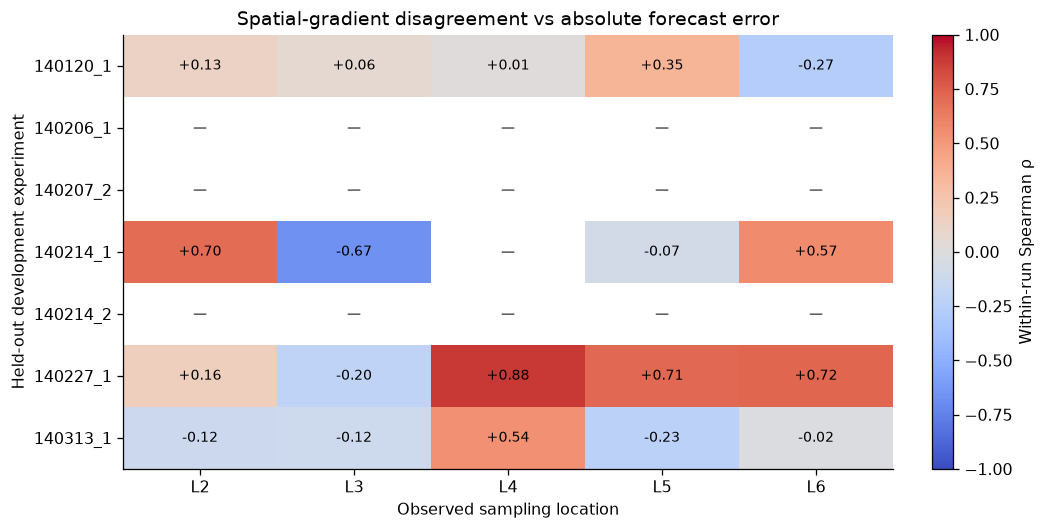

Within-run, within-location Spearman associations (n≥7; otherwise unavailable):


location                           L2     L3     L4     L5     L6
dataset          experiment                                      
Development      140120_1.xlsx  0.127  0.061  0.014  0.348 -0.269
                 140214_1.xlsx  0.700 -0.667    NaN -0.071  0.567
                 140227_1.xlsx  0.162 -0.204  0.883  0.713  0.720
                 140313_1.xlsx -0.124 -0.116  0.543 -0.234 -0.022
Independent test 140207_1.xlsx  0.018 -0.484  0.610 -0.024  0.294

Test within-location associations:


,location,n,spearman_rho
35,L2,18,0.018
36,L3,18,-0.484
37,L4,13,0.610
38,L5,16,-0.024
39,L6,18,0.294


Predicted-profile inversion rate by experiment:


n  fraction_with_inversion
dataset          experiment                                 
Development      140120_1.xlsx  105                    0.067
                 140206_1.xlsx   38                    0.684
                 140207_2.xlsx   38                    1.000
                 140214_1.xlsx   55                    0.836
                 140214_2.xlsx   38                    0.000
                 140227_1.xlsx  206                    0.000
                 140313_1.xlsx  216                    1.000
Independent test 140207_1.xlsx  106                    0.132

In [9]:
# Within-experiment, within-location consistency: avoid pooled scale confounding.
from scipy.stats import spearmanr
sp_run=[]
for (ds,run,loc),g in sp.groupby(['dataset','experiment','location']):
    can_compute=len(g)>=7 and g.gradient_disagreement.nunique()>2 and g.abs_error.nunique()>2
    rho=spearmanr(g.gradient_disagreement,g.abs_error).statistic if can_compute else np.nan
    sp_run.append({'dataset':ds,'experiment':run,'location':loc,'n':len(g),'spearman_rho':rho})
sp_run=pd.DataFrame(sp_run)
mat=sp_run.query('dataset=="Development"').pivot(index='experiment',columns='location',values='spearman_rho').reindex(columns=['L2','L3','L4','L5','L6'])
fig,ax=plt.subplots(figsize=(9,4.5),constrained_layout=True)
img=ax.imshow(mat.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm',aspect='auto')
ax.set_xticks(range(len(mat.columns)),mat.columns)
ax.set_yticks(range(len(mat.index)),[s.replace('.xlsx','') for s in mat.index])
ax.set(title='Spatial-gradient disagreement vs absolute forecast error',xlabel='Observed sampling location',ylabel='Held-out development experiment')
for i in range(len(mat.index)):
    for j in range(len(mat.columns)):
        v=mat.iloc[i,j]
        ax.text(j,i,'—' if pd.isna(v) else f'{v:+.2f}',ha='center',va='center',fontsize=9,color='black')
fig.colorbar(img,ax=ax,label='Within-run Spearman ρ')
plt.show()
print('Within-run, within-location Spearman associations (n≥7; otherwise unavailable):')
display(sp_run.pivot_table(index=['dataset','experiment'],columns='location',values='spearman_rho',aggfunc='first').round(3))
print('Test within-location associations:')
display(sp_run.query('dataset=="Independent test"')[['location','n','spearman_rho']].round(3))
print('Predicted-profile inversion rate by experiment:')
display(inv.groupby(['dataset','experiment']).inversion_count.agg(n='size',fraction_with_inversion=lambda x:(x>0).mean()).round(3))


### Spatial-gradient disagreement: consistency across locations and experiments

The pooled spatial-gradient scatter suggests a positive relationship between gradient disagreement and absolute forecast error, but **that pattern does not persist consistently within individual locations and experiments**. The development location-wise Spearman correlations are **−0.009 (L2), +0.204 (L3), +0.858 (L4), −0.024 (L5), and +0.087 (L6)**. On the independent test they are **+0.018, −0.484, +0.610, −0.024, and +0.294**, respectively. L4 is the only location with a pronounced positive association in both splits. Its development association is concentrated in two longer experiments (ρ=+0.883 in 140227_1 and +0.543 in 140313_1); it is approximately zero in 140120_1 (ρ=+0.014). Shorter experiments provide too few eligible observations for a reliable within-run estimate.

The run-by-location heatmap is the decisive consistency check. In particular, **L3 reverses sign** between the pooled development result and the independent test, while L5 remains near zero in both. The apparent strong positive association when pooling all locations within a run is therefore not evidence of a shared spatial-error mechanism: location-specific concentration scales and forecast-error magnitudes differ substantially.

There is also an important *structural dependency* in this diagnostic. The gradient-disagreement measure contains the model prediction at the observed location, and absolute forecast error contains that same prediction. A positive correlation can arise mechanically even without a genuine failure to learn spatial coupling. The historical neighboring concentration was measured asynchronously, so its difference from the current predicted gradient can also reflect actual evolution between sampling times. **Consequently, gradient disagreement cannot be identified as a general root cause of forecast error from these correlations.** The L4 association warrants further investigation, but does not establish a transport or spatial-coupling failure.

The separate predicted-profile diagnostic does reveal **experiment-dependent spatial behavior**: at least one adjacent L2–L6 inversion occurs in **47.8% of development** and **13.2% of test** forecast profiles. Development rates vary from **0%** in 140214_2 and 140227_1 to **100%** in 140207_2 and 140313_1. This sharp variation indicates that the learned spatial ordering is sensitive to the experiment or operating regime; the inversion count alone cannot determine whether any particular profile is physically invalid. These outputs should be interpreted as a model-coherence diagnostic rather than an independently verified instantaneous concentration profile.

**Root-cause implication.** The evidence does **not** support a universal relationship between spatial-gradient disagreement and error. The stronger supported explanation remains inaccurate location-dependent concentration adjustments, with spatial-output ordering varying markedly by experiment. This distinguishes a measurable model-output instability from an unproven physical transport mechanism.

## 8 | L6: concentration-dependent overprediction rather than simple range extrapolation

The highest sampling position, L6, combines comparatively large absolute changes with a systematic positive test residual. To distinguish an unfamiliar concentration range from a biased learned response, we compare the observed test concentrations with the development distribution and examine signed residuals **within** the test range. A uniform vertical offset would yield similar errors across concentrations; a declining residual with increasing measured concentration indicates that the model responds differently across the operating concentration range.

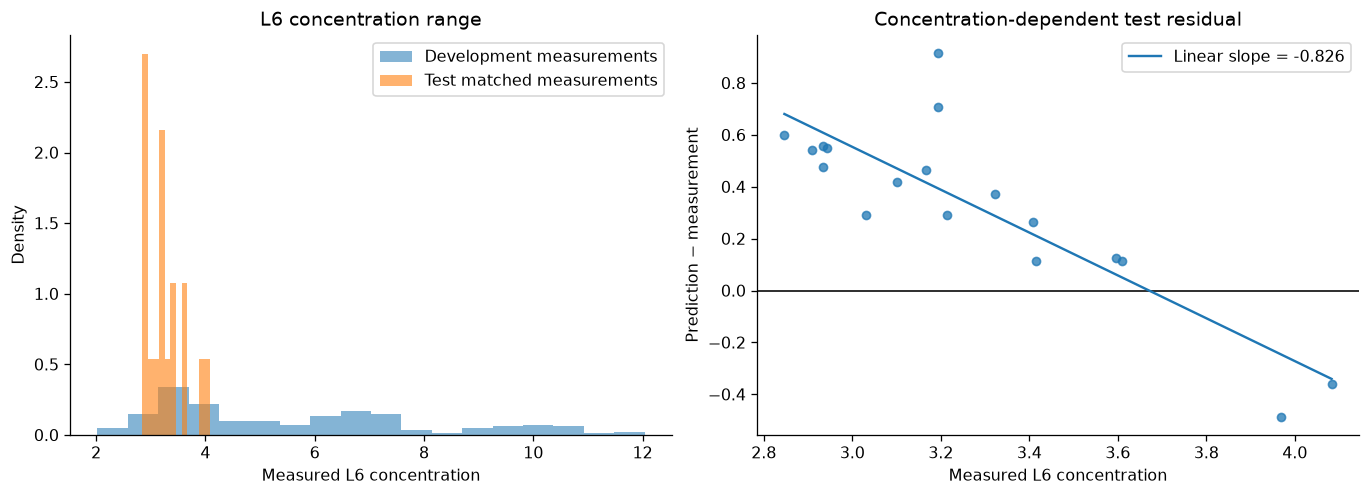

Development L6 5–95% interval: [2.6942, 10.4669] | Test outside: 0.0% (18 observations)
Test L6 lower-half mean residual: 0.5520 (n=10); upper-half: 0.0538 (n=8)
Test L6 residual–concentration Spearman rho: -0.794


**Finding.** **0.0%** of matched test L6 concentrations lie outside the central 90% of the development measured distribution. Mean signed errors are **+0.552** in the lower and **+0.054** in the upper half of the test concentration range. The direction and magnitude of this difference indicate whether a single constant offset adequately describes the L6 error or whether the error varies with concentration. The positive residual at low concentrations and near-zero residual at higher concentrations identifies a concentration-dependent calibration error; a single constant correction would not address both regions equally.

In [10]:
loc='L6';train_l6=observed(outer.query('history==12 and horizon==1 and training_objective=="noise" and input_mode=="combined"'))
train_l6=train_l6[train_l6.location.eq(loc)]
test_l6=test[test.location.eq(loc)].copy()
# Only one observation per run/time/location is used. The development prediction set is not a training label distribution:
# reconstruct actual development measured L6 observations directly from raw experiment sheets.
training_values=[]
for run in sorted(set(dev.experiment)):
 a=runs[run];training_values.extend(pd.to_numeric(a.loc[a.label.eq(6),'AT400'],errors='coerce').dropna().tolist())
training_values=np.array(training_values,float)
fig,axes=plt.subplots(1,2,figsize=(11.8,4.2),constrained_layout=True)
axes[0].hist(training_values,bins=18,density=True,alpha=.55,label='Development measurements');axes[0].hist(test_l6.y_true,bins=12,density=True,alpha=.6,label='Test matched measurements');axes[0].set(xlabel='Measured L6 concentration',ylabel='Density',title='L6 concentration range');axes[0].legend()
axes[1].scatter(test_l6.y_true,test_l6.residual,s=26,alpha=.75);axes[1].axhline(0,color='black',lw=1)
if len(test_l6)>2 and test_l6.y_true.nunique()>2:
 b,a=np.polyfit(test_l6.y_true,test_l6.residual,1);xx=np.linspace(test_l6.y_true.min(),test_l6.y_true.max(),100);axes[1].plot(xx,a+b*xx,label=f'Linear slope = {b:.3f}');axes[1].legend()
axes[1].set(xlabel='Measured L6 concentration',ylabel='Prediction − measurement',title='Concentration-dependent test residual');plt.show()
lo,hi=np.quantile(training_values,[.05,.95]);outside=np.mean((test_l6.y_true<lo)|(test_l6.y_true>hi))
mid=test_l6.y_true.median();low=test_l6[test_l6.y_true<=mid];high=test_l6[test_l6.y_true>mid]
print(f'Development L6 5–95% interval: [{lo:.4f}, {hi:.4f}] | Test outside: {outside:.1%} ({len(test_l6)} observations)')
print(f'Test L6 lower-half mean residual: {low.residual.mean():.4f} (n={len(low)}); upper-half: {high.residual.mean():.4f} (n={len(high)})')
print(f'Test L6 residual–concentration Spearman rho: {spearmanr(test_l6.y_true,test_l6.residual).statistic:.3f}')
display(Markdown(f'**Finding.** **{outside:.1%}** of matched test L6 concentrations lie outside the central 90% of the development measured distribution. Mean signed errors are **{low.residual.mean():+.3f}** in the lower and **{high.residual.mean():+.3f}** in the upper half of the test concentration range. The direction and magnitude of this difference indicate whether a single constant offset adequately describes the L6 error or whether the error varies with concentration. The positive residual at low concentrations and near-zero residual at higher concentrations identifies a concentration-dependent calibration error; a single constant correction would not address both regions equally.'))

### Interpretation — L6 error changes across the observed concentration range

The central 90% interval of development L6 measurements is **[2.694, 10.467]**. All **18 matched independent-test L6 observations** fall within that *marginal concentration interval*. Consequently, the test bias is not explained simply by L6 measurements falling outside this particular development range; the underlying multivariate operating conditions can nevertheless differ.

The model's signed error is **+0.552 on average for the lower half of test L6 concentrations (n=10)**, compared with **+0.054 for the upper half (n=8)**. The residual–observed-concentration Spearman coefficient is **−0.794**. In plain terms, **the Transformer substantially overpredicts low measured L6 concentrations, while its average error is much smaller at higher measured concentrations**. A single constant offset would not describe that pattern well. The small, temporally related test sample limits precision, and conditioning residuals on observed concentration can introduce statistical coupling; the result is a diagnostic of calibration across concentration levels, not an identified physical cause.

**Connection to the broader diagnosis.** L6 exhibits relatively large absolute between-dwell concentration changes, while its learned corrections are frequently too large or misdirected. The concentration-stratified residuals reveal an additional **state-dependent calibration error** at this location. This is a specific manifestation of the broader difficulty estimating concentration evolution, not a reason to treat L6 as the sole source of forecasting failure.

## 9 | Integrated root-cause diagnosis

The preceding analyses identify the model's **directly observed failure**—inaccurate location-specific concentration adjustments—and test the physical and informational conditions under which it arises. The evidence table below consolidates the quantitative findings; the final interpretation distinguishes the principal failure from contributing conditions and secondary spatial or location-specific effects.

In [11]:
contrib=correction.groupby(['split','location']).agg(direction_accuracy=('direction_accuracy','mean'),fraction_helpful=('fraction_helpful','mean'),correction_to_change=('correction_to_change','mean'))
strong=valid[(valid.n_runs>=5)&(valid.median_abs_rho>=.3)&(valid.sign_agreement>=.8)]
evidence=pd.DataFrame([
 ('Intrinsic location dynamics',f"Median within-run scaled changes range {location_summary.median_scaled_change.min():.3f}–{location_summary.median_scaled_change.max():.3f} across L2–L6",'Measured between-dwell dynamics; assess alongside concentration scale'),
 ('Learned forecast correction',f"Helpful on {(dev.gain>0).mean():.1%} development and {(test.gain>0).mean():.1%} test paired forecasts",'Direct evidence of erroneous learned corrections'),
 ('Transferable process-change sensitivity',f"{len(strong)} of {len(valid)} eligible location/sensor pairs meet prespecified |ρ|≥0.3, sign agreement≥0.8, and ≥5-run thresholds",'Association screening; consistency across experiments is the key criterion'),
 ('Measurement staleness',f"{(age_stats.query('split=="Development"').rho_age_excess_error>0).sum()}/{len(age_stats.query('split=="Development"'))} eligible development strata show positive age–excess-error association",'Age association assessed separately within experiment and location'),
 ('Operating-regime novelty',f"{(slope.rho_abs_error>0).sum()}/{len(slope)} held-out runs show positive novelty–absolute-error association",'Operating-state association varies across experiments'),
 ('Operating-condition-dependent residual',f"{len(strong_regime)}/{len(eligible)} eligible sensor/location pairs meet cross-run stability thresholds",'Forecast-origin regime association; not a kinetic parameter estimate'),
 ('L6 concentration dependence',f"Test L6 lower/upper concentration-half mean residuals {low.residual.mean():+.3f}/{high.residual.mean():+.3f}",'Concentration-dependent error in a limited independent-test sample')],columns=['Hypothesis','Observed quantitative evidence','Interpretation limit'])
display(evidence.style.set_properties(subset=['Observed quantitative evidence'],**{'white-space':'pre-wrap'}))
print('Principal model failure: inaccurate location-specific concentration changes. Measured dwell-to-dwell dynamics and the learned correction characterize the failure; information age and operating-regime analyses test candidate contributing factors.')

# Mechanistic/regime evidence summary (criteria fixed before reviewing associations).
print(f'Operating-condition residual associations: {len(strong_regime)} of {len(eligible)} eligible sensor/location pairs pass the cross-experiment consistency screen.')
print('Physical interpretation: absorber throughput, thermal state and pressure can alter gas–liquid contact and transport delays; the analysis tests their relationship to learned residuals, not kinetic parameters.')


,Hypothesis,Observed quantitative evidence,Interpretation limit
0,Intrinsic location dynamics,Median within-run scaled changes range 0.544–0.886 across L2–L6,Measured between-dwell dynamics; assess alongside concentration scale
1,Learned forecast correction,Helpful on 25.9% development and 30.1% test paired forecasts,Direct evidence of erroneous learned corrections
2,Transferable process-change sensitivity,"1 of 80 eligible location/sensor pairs meet prespecified |ρ|≥0.3, sign agreement≥0.8, and ≥5-run thresholds",Association screening; consistency across experiments is the key criterion
3,Measurement staleness,13/29 eligible development strata show positive age–excess-error association,Age association assessed separately within experiment and location
4,Operating-regime novelty,5/8 held-out runs show positive novelty–absolute-error association,Operating-state association varies across experiments
5,Operating-condition-dependent residual,0/42 eligible sensor/location pairs meet cross-run stability thresholds,Forecast-origin regime association; not a kinetic parameter estimate
6,L6 concentration dependence,Test L6 lower/upper concentration-half mean residuals +0.552/+0.054,Concentration-dependent error in a limited independent-test sample


Principal model failure: inaccurate location-specific concentration changes. Measured dwell-to-dwell dynamics and the learned correction characterize the failure; information age and operating-regime analyses test candidate contributing factors.
Operating-condition residual associations: 0 of 42 eligible sensor/location pairs pass the cross-experiment consistency screen.
Physical interpretation: absorber throughput, thermal state and pressure can alter gas–liquid contact and transport delays; the analysis tests their relationship to learned residuals, not kinetic parameters.


### Synthesis — what explains the forecasting errors

**Primary observed failure: miscalibrated concentration evolution.** The most direct evidence compares each Transformer forecast with the last completed-dwell concentration available at prediction time and the concentration subsequently measured. At L3–L6, typical predicted adjustments are larger than typical realized changes; at L4 and L6, direction agreement is also limited. In relatively stable periods the learned adjustment adds substantially more absolute error than during larger measured changes. The failure is therefore not simply a high forecast MAE: the fitted model frequently assigns an incorrect **magnitude or direction to the intervening concentration change**.

**Why the system makes that correction difficult.** The analyzer revisits each location after approximately **12.23 minutes**, while the forecast horizon is approximately **43 seconds**. Genuine CO₂ changes over completed-dwell intervals differ markedly by location. The Transformer must combine an intermittently refreshed, location-specific concentration reference with recent process measurements. Tested process–CO₂ change associations vary in sign across experiments, and no examined single sensor has a reproducible signed-residual association under the predefined consistency screen. These findings support **context-dependent physical response and incomplete concentration-state information** as contributing conditions for unreliable learned adjustments; they do not establish that process measurements are intrinsically uninformative.

**When the failure intensifies.** Operating-state novelty is positively associated with absolute error in **five of eight** experiments, indicating an experiment-dependent generalization penalty rather than a universal effect. Observation-age relationships also vary across experiment–location groups. Both diagnostics support the view that the correction depends on the operating trajectory and information available at the forecast origin, not on measurement age or novelty alone.

**Spatial structure: important but not the common error mechanism.** Predicted L2–L6 ordering varies sharply by experiment, including runs with no inversions and runs with inversions in every predicted profile. Yet the relationship between spatial-gradient disagreement and observed-location forecast error is **not consistent across locations or runs**; L4 is the principal exception. Because the gradient diagnostic and the error share the same predicted value, this association is not independent evidence of a transport failure. Spatial-output instability is therefore a **secondary model-coherence finding**, not an established absorber-wide root cause.

**Location-specific calibration at L6.** On the independent test, average L6 overprediction is **+0.552** at lower measured concentrations versus **+0.054** at higher concentrations, despite all 18 matched observations falling inside the central development concentration interval. This identifies a **concentration-dependent calibration defect** within the broader problem of estimating local concentration changes; it is not a blanket explanation for L2–L5.

**Modeling consequence.** The evidence prioritizes better **location- and state-conditional calibration of forecast increments**, especially when the available history suggests little actual change, and improved representation of asynchronous concentration information. More physically constrained transport-response modeling would require independently verified delay and boundary-condition information. The loss-objective and history–horizon rankings have already been evaluated during model selection; the diagnostics here do not isolate a separate mechanism for those rankings and do not warrant repeating them.